# Randomized Benchmarking

In [3]:
from qiskit.quantum_info import random_clifford, Clifford
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import (
    NoiseModel,
    depolarizing_error,
    thermal_relaxation_error,
    amplitude_damping_error,
    ReadoutError,
)
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt

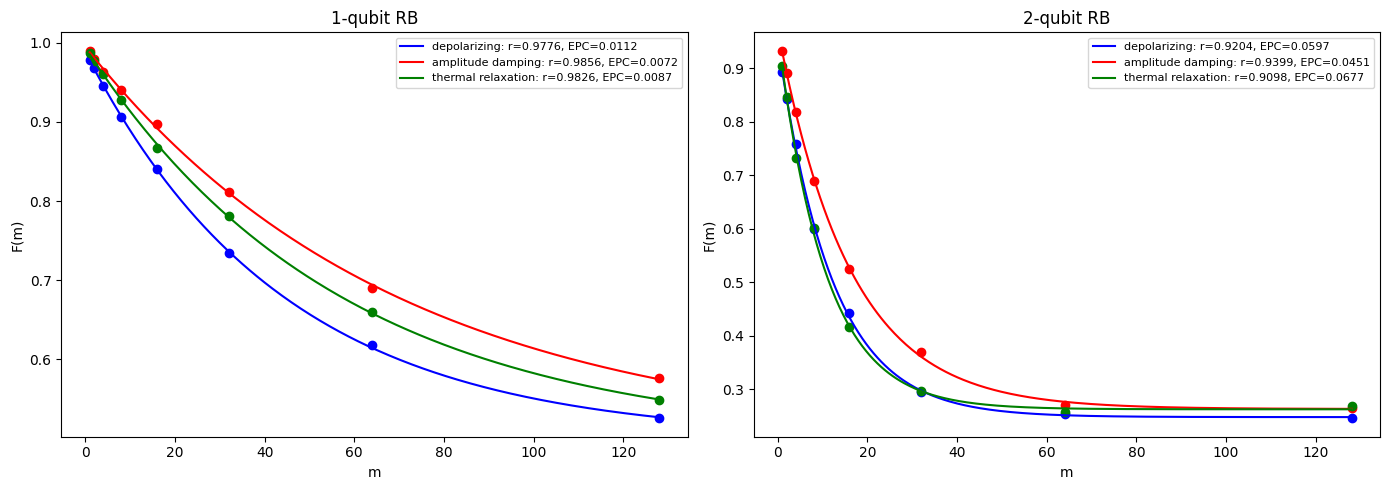

In [11]:
'''
Creating a method to select a noise model based oon inputs
'''

def make_noise_model(noise_type, params, n_qubits):
    nm = NoiseModel()
    if noise_type == "depolarizing":
        error1q = depolarizing_error(params["input_prob"], 1)
        nm.add_all_qubit_quantum_error(error1q, "u3")
        if n_qubits > 1:
            error2q = depolarizing_error(params["input_prob"], 2)
            nm.add_all_qubit_quantum_error(error2q, "cx")
        # this line says everytime a cicruit has a single qubit 
        # gate (u3) or a two qubit gate (cx) apply the depolarizing error
        # u3 is the gate that every other single qubit gate compiles to
        # Λ(ρ) = r·ρ + (1−r)·I/d   params: {"input_prob": r}

    elif noise_type == "amplitude_damping":
        error1q = amplitude_damping_error(params["input_prob"])
        nm.add_all_qubit_quantum_error(error1q, ["u3"])
        if n_qubits > 1:
            error2q = error1q.expand(error1q)
            nm.add_all_qubit_quantum_error(error2q, ["cx"])
        # Λ: |1⟩ → |0⟩ with prob gamma   params: {"input_prob": gamma}
        #K₀ = [[1, 0], [0, √(1−γ)]] K₁ = [[0, √γ], [0, 0]]


    elif noise_type == "thermal_relaxation":
        '''
        Quick theory: Thermal relaxation — it models two physical decay processes on real hardware: 
        T1 — energy relaxation: excited qubit |1⟩ spontaneously decays to |0⟩ over time T1
        T2 — dephasing: qubit loses phase coherence (the X/Y components of the Bloch vector shrink) over time T2
        '''
        
        error1q = thermal_relaxation_error(params["T1"], params["T2"], params["tgate"])
        nm.add_all_qubit_quantum_error(error1q, ["u3"])
        if n_qubits > 1:
            error_cx = thermal_relaxation_error(params["T1"], params["T2"], params["tgate"] * 2)
            error2q = error_cx.expand(error_cx)
            nm.add_all_qubit_quantum_error(error2q, ["cx"])
        # Λ: T1 decay + T2 dephasing over gate time tgate, not this not the T gate. params: {"T1": ns, "T2": ns, "tgate": ns}  with T2 <= 2*T1
        #p1 = exp(−t/T1) — T1 decay factorp2 = exp(−t/T2) — T2 decay factor
        #K₀ = [[1, 0], [0, √p1]] K₁ = [[0, √(1−p1)], [0, 0]] K₂ = [[0, 0], [0, √(p2 − p1)]]  ← only exists when p2 > p1 K₀, K₁ — same as amplitude damping, capturing T1 decay K₂ — pure dephasing on top of T1, capturing the extra T2 decay

    return nm


def build_rb_circuit(n, m, interleaved=None):
    qc = QuantumCircuit(n, n)
    D = Clifford(qc) # initially this will be I
    #Clifford(qc) takes a quantum circuit and returns the Clifford object representing that circuit's unitary action. Since qc at this point is an empty circuit (no gates yet), Clifford(qc) is just the identity.
    for _ in range(m):
        C = random_clifford(n)
        qc.append(C, range(n)) # apply C to all qubits (range(n))
        D = D.compose(C) # adding now so that we can eventually
        # find the inv.

    inv = D.adjoint() # find the inverse of D
    qc.append(inv, range(n)) # apply the inverse to all qubits
    qc.measure(range(n), range(n)) # measure all qubits
    return qc


def run_experiment(noise_model, m_values, n_qubits, independent_sequences_per_m, shots):
    simulator = AerSimulator(noise_model=noise_model)
    results = {}
    for m in m_values:
        survival_probs = []
        for _ in range(independent_sequences_per_m):
            qc = build_rb_circuit(n_qubits, m, interleaved=None)
            qc = transpile(qc, basis_gates=["cx", "u3", "id", "reset", "measure"], optimization_level=0)
            counts = simulator.run(qc, shots=shots).result().get_counts()
            survival_prob = counts.get("0"*n_qubits, 0) /shots # look up all 0 strings in counts. Counts is dict like {"0": 950, "1": 74}. If "0" not found return 0 as default.
            survival_probs.append(survival_prob)
        results[m] = np.mean(survival_probs) # this is F(m, |0..0>)
    return results


def fit_rbdata(results, n_qubits):
    m_vals = np.array(sorted(results.keys()))
    f_vals = np.array([results[m] for m in m_vals])

    def rb_decay(m, A, r, B):
        return A * r**m + B
    
    p0 = [0.5, 0.99, 0.5]
    popt, _ = curve_fit(rb_decay, m_vals, f_vals, p0=p0, bounds=([0,0,0], [1,1,1]))
    A, r, B = popt

    d = 2**n_qubits
    error_per_clifford = (d-1)/d * (1-r)
    return {"A": A, "r": r, "B": B, "EPC": error_per_clifford}



def run_rb(n_qubits):
    m_values = [1, 2, 4, 8, 16, 32, 64, 128] # logarthimically spaced
    independent_sequences_per_m = 30
    shots = 1024

    nm_ad = make_noise_model("amplitude_damping", {"input_prob": 0.01}, n_qubits)
    results_ad = run_experiment(nm_ad, m_values, n_qubits, independent_sequences_per_m, shots)

    nm_dep   = make_noise_model("depolarizing",       {"input_prob": 0.01}, n_qubits)
    results_dep   = run_experiment(nm_dep,   m_values, n_qubits, independent_sequences_per_m, shots)

    nm_therm = make_noise_model("thermal_relaxation", {"T1": 50000, "T2": 70000, "tgate": 500}, n_qubits)
    results_therm = run_experiment(nm_therm, m_values, n_qubits, independent_sequences_per_m, shots)

    '''For thermal relaxation with T1=50000ns, T2=70000ns, tgate=500:
    The decay per gate is controlled by:
    p1 = exp(−500/50000) = exp(−0.01) ≈ 0.99 — T1 survival
    p2 = exp(−500/70000) = exp(−0.007) ≈ 0.993 — T2 survival
    So per gate: ~1% chance of energy decay (T1) and ~0.7% chance of pure dephasing (T2).
    Key difference from the other two: two independent decay processes happening simultaneously — the qubit is both losing energy AND losing phase coherence during the gate. This makes it the most physically realistic of the three noise models.
    The curve will decay similarly to depolarizing (~1% per gate) but the shape is slightly different because T1 and T2 contribute differently to the RB signal.'''

    # fit all 3
    fit_dep   = fit_rbdata(results_dep,   n_qubits)
    fit_ad    = fit_rbdata(results_ad,    n_qubits)
    fit_therm = fit_rbdata(results_therm, n_qubits)

    # plot
    m_smooth = np.linspace(1, 128, 300)
    experiments = [
    ("depolarizing",       results_dep,   fit_dep,   "blue"),
    ("amplitude damping",  results_ad,    fit_ad,    "red"),
    ("thermal relaxation", results_therm, fit_therm, "green"),
    ]

    return experiments


m_smooth = np.linspace(1, 128, 300)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, n_qubits in zip(axes, [1, 2]):
    experiments = run_rb(n_qubits)
    for name, results, fit, color in experiments:
        m_vals = np.array(sorted(results.keys()))
        f_vals = np.array([results[m] for m in m_vals])
        f_smooth = fit["A"] * fit["r"]**m_smooth + fit["B"]
        label = f"{name}: r={fit['r']:.4f}, EPC={fit['EPC']:.4f}"
        ax.scatter(m_vals, f_vals, color=color)
        ax.plot(m_smooth, f_smooth, color=color, label=label)
    ax.set_title(f"{n_qubits}-qubit RB")
    ax.set_xlabel("m")
    ax.set_ylabel("F(m)")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()


## Standard RB Results — Analysis

### Key Observations

- **ErrorPerClifford (EPC) scales ~6x from 1-qubit to 2-qubit** across all noise types — 2-qubit Cliffords decompose into many more `cx` + `u3` gates, so error accumulates faster per sequence step

- **Noise floor drops from ~0.5 to ~0.25** — exactly `1/d` where `d = 2ⁿ`, confirming the maximally mixed state limit is correctly reached in both cases

- **Amplitude damping decays slowest in both 1 and 2-qubit cases** — because it only drives |1⟩ → |0⟩, the noise is asymmetric and partially biased toward the |0...0⟩ survival state, giving it an artificially higher `r`

- **Thermal relaxation is the most physically realistic** — it combines T1 energy decay and T2 dephasing simultaneously, modelling two independent decoherence processes per gate

- **Depolarizing decays fastest** — symmetric noise in all directions (X, Y, Z errors) with no bias, resulting in the highest EPC for a given error probability
